# Preguntar

Este análisis se centrará en una Exploración de Datos (EDA) y eventualmente en modelos de segmentación o predicción. Algunas preguntas orientadoras podrían ser:

- ¿Cuáles son los sectores económicos más representativos en Valledupar?
- ¿Qué tipo de persona (natural o jurídica) predomina?
- ¿Cómo varía la formalización empresarial por sector o año de matrícula?

#Preparar

En este paso nos encargaremos de realizar una exploracion de nuestros datos, por ejemplo como esta conformado nuestro base datos, tipos de variables, valores nulos, outliers etc

In [ ]:
!pip install empiricaldist pyjanitor missingno


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 215.4/215.4 kB 7.7 MB/s eta 0:00:00
  Created wheel for empiricaldist: filename=empiricaldist-0.9.0-py3-none-any.whl size=14296 sha256=1bd732eaa5b6ed64136d7ffccd21dde59e15e763e74de59a9a2edadf202ce16a
  Stored in directory: /root/.cache/pip/wheels/96/04/f1/a934ef1f5f3db621dc39566b2c7de45b8c6916044be6a9c9ac
Successfully built empiricaldist


In [ ]:
!pip install upsetplot

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for upsetplot: filename=upsetplot-0.9.0-py3-none-any.whl size=24866 sha256=ae186de66ca176eccbe6b20fe8299f25399cd5f48ced454a2ba9547a44f4c9f6
  Stored in directory: /root/.cache/pip/wheels/7b/ce/88/1d0bce5b2680165c29c3e68416325e79674d5a9f422d037996
Successfully built upsetplot


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats
import seaborn as sns
import empiricaldist
import missingno
import janitor
import upsetplot
from google.colab import drive
from scipy.stats import chi2_contingency

In [ ]:
%matplotlib inline
sns.set_style(style='whitegrid')
sns.set_context('notebook')
plt.rcParams['figure.figsize'] = (18, 9.4)

raya = '-' * 100

In [ ]:
matriculas = pd.read_csv("/content/drive/MyDrive/python/Portafolio/Personas Naturales y Juridicas/PERSONAS_NATURALES_Y_JUR_DICAS_ACTIVAS_MATRICULADAS_EN_VALLEDUPAR_20250629.csv")

In [ ]:
%run "/content/drive/MyDrive/python/Portafolio/Personas Naturales y Juridicas/pandas-missing-extension.ipynb"


In [ ]:
matriculas

,MAT,OJ,RAZON SOCIAL,FEC-MATRICULA,ULT-ANO_REN,ACTIVIDAD ECONÓMICA,DESCRIPCION ACTIVIDAD,TAMAÑO
0,123514,SOCIEDAD POR ACCIONES SIMPLIFICADA (SAS),SERVIGENERAL TRABAJO RESPONSABLE SAS,20140812,2020,T. ACTIVIDADES DE LOS HOGARES INDIVIDUALES EN ...,T9700 ** Actividades de los hogares individual...,MICROEMPRESA
1,163496,PERSONA NATURAL,ESCOBAR GARCIA NANCY PATRICIA,20190626,2021,S. OTRAS ACTIVIDADES DE SERVICIOS,S9602 ** Peluqueria y otros tratamientos de be...,MICROEMPRESA
2,162978,PERSONA NATURAL,MOSQUERA ARBOLEDA MARIA ADRIANA,20190605,2020,S. OTRAS ACTIVIDADES DE SERVICIOS,S9602 ** Peluqueria y otros tratamientos de be...,MICROEMPRESA
3,147708,PERSONA NATURAL,RAMOS GOMEZ JULIO EDUARDO,20170915,2021,S. OTRAS ACTIVIDADES DE SERVICIOS,S9529 ** Mantenimiento y reparacion de otros e...,MICROEMPRESA
4,147348,PERSONA NATURAL,BAYONA ROJAS LUISA ALEJANDRA,20170829,2019,S. OTRAS ACTIVIDADES DE SERVICIOS,S9602 ** Peluqueria y otros tratamientos de be...,MICROEMPRESA
...,...,...,...,...,...,...,...,...
17255,65115,PERSONA NATURAL,PUERTA JIMENEZ JAVIER,20021113,2019,C. INDUSTRIA MANUFACTURERA,C1081 ** Elaboracion de productos de panaderia,MICROEMPRESA
17256,64761,PERSONA NATURAL,PACHECO MINDIOLA IRIABET,20020924,2020,C. INDUSTRIA MANUFACTURERA,C2023 ** Fabricacion de jabones y detergentes ...,MICROEMPRESA
17257,178162,PERSONA NATURAL,CAMPO SANTANA DAYANNA,20210211,2021,G. COMERCIO,G4752 ** Comercio al por menor de articulos de...,MICROEMPRESA
17258,64716,PERSONA NATURAL,CARRILLO MANJARRES LINO JESUS,20020919,2020,C. INDUSTRIA MANUFACTURERA,C3230 ** Fabricacion de articulos y equipo par...,MICROEMPRESA


In [ ]:
print(matriculas.shape,'=',matriculas.size)

(17260, 8) = 138080


tenemos una cantidad de datos inicial de 138.080, que son 17.260 filas con 8 columnas.

**Ahora vamos a ver la informacion de nuestros datos resolviendo preguntas como  ¿De que tipo es cada variable? ¿Se debe corregir alguna variable?**

In [ ]:

matriculas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17260 entries, 0 to 17259
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   MAT                    17260 non-null  object
 1   OJ                     17260 non-null  object
 2   RAZON SOCIAL           17260 non-null  object
 3   FEC-MATRICULA          17260 non-null  int64 
 4   ULT-ANO_REN            17260 non-null  int64 
 5   ACTIVIDAD ECONÓMICA    17260 non-null  object
 6   DESCRIPCION ACTIVIDAD  17260 non-null  object
 7   TAMAÑO                 17260 non-null  object
dtypes: int64(2), object(6)
memory usage: 1.1+ MB


In [ ]:
#Cambiamos el nombre
matriculas = (
    matriculas.rename(
        columns={
            'MAT' : 'Matriculas',
            'OJ' : 'Organizacion_Juridica',
            'RAZON SOCIAL' : 'Razon_Social',
            'FEC-MATRICULA' : 'Fecha_Matricula',
            'ULT-ANO_REN' : 'Año_Renovacion',
            'ACTIVIDAD ECONÓMICA' : 'Actividad_Economica',
            'DESCRIPCION ACTIVIDAD' : 'Descripcion_Actividad',
            'TAMAÑO': 'Clasificacion'
        }
        )
    )

Confirmamos  que se cambio el nombre correctamente

> Añadir blockquote



In [ ]:
matriculas.columns

Index(['Matriculas', 'Organizacion_Juridica', 'Razon_Social',
       'Fecha_Matricula', 'Año_Renovacion', 'Actividad_Economica',
       'Descripcion_Actividad', 'Clasificacion'],
      dtype='object')

**Cuando se ejecuto el codigo .info() se puedo observar que la fecha de la matricula se encuentra en un formato YYYYMMDD pero como de tipo entero, y la columna del ultimo año se debera cambiar a tipo objecto porque no nos sirve para calculos**

In [ ]:
matriculas['Fecha_Matricula'] = pd.to_datetime(matriculas['Fecha_Matricula'], format='%Y%m%d')
matriculas['Año_Renovacion'] = matriculas['Año_Renovacion'].astype(str)

**Rectificamos nuevamente**

In [ ]:
matriculas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17260 entries, 0 to 17259
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Matriculas             17260 non-null  object        
 1   Organizacion_Juridica  17260 non-null  object        
 2   Razon_Social           17260 non-null  object        
 3   Fecha_Matricula        17260 non-null  datetime64[ns]
 4   Año_Renovacion         17260 non-null  object        
 5   Actividad_Economica    17260 non-null  object        
 6   Descripcion_Actividad  17260 non-null  object        
 7   Clasificacion          17260 non-null  object        
dtypes: datetime64[ns](1), object(7)
memory usage: 1.1+ MB


En este paso nos dimos cuenta que el codigo para cada Descripcion de la activididad esta repetida, para mejorar los analisis lo que se hara es dividir la columna:

In [ ]:
matriculas[['Codigo_actividad', 'Nombre_actividad']] = matriculas['Descripcion_Actividad'].str.split(r' \*\* ', expand=True)
matriculas = matriculas.drop('Descripcion_Actividad', axis=1)

In [ ]:
matriculas.head()

,Matriculas,Organizacion_Juridica,Razon_Social,Fecha_Matricula,Año_Renovacion,Actividad_Economica,Clasificacion,Codigo_actividad,Nombre_actividad
0,123514,SOCIEDAD POR ACCIONES SIMPLIFICADA (SAS),SERVIGENERAL TRABAJO RESPONSABLE SAS,2014-08-12,2020,T. ACTIVIDADES DE LOS HOGARES INDIVIDUALES EN ...,MICROEMPRESA,T9700,Actividades de los hogares individuales como e...
1,163496,PERSONA NATURAL,ESCOBAR GARCIA NANCY PATRICIA,2019-06-26,2021,S. OTRAS ACTIVIDADES DE SERVICIOS,MICROEMPRESA,S9602,Peluqueria y otros tratamientos de belleza
2,162978,PERSONA NATURAL,MOSQUERA ARBOLEDA MARIA ADRIANA,2019-06-05,2020,S. OTRAS ACTIVIDADES DE SERVICIOS,MICROEMPRESA,S9602,Peluqueria y otros tratamientos de belleza
3,147708,PERSONA NATURAL,RAMOS GOMEZ JULIO EDUARDO,2017-09-15,2021,S. OTRAS ACTIVIDADES DE SERVICIOS,MICROEMPRESA,S9529,Mantenimiento y reparacion de otros efectos pe...
4,147348,PERSONA NATURAL,BAYONA ROJAS LUISA ALEJANDRA,2017-08-29,2019,S. OTRAS ACTIVIDADES DE SERVICIOS,MICROEMPRESA,S9602,Peluqueria y otros tratamientos de belleza


Observaremos si en nuestro DF hay valores nulos utilizando graficas tambien

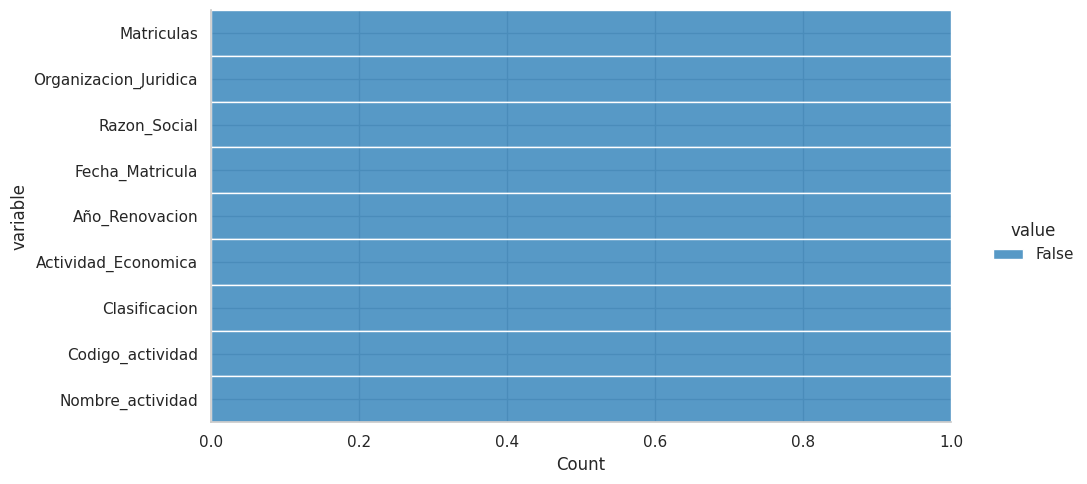

In [ ]:
(
    matriculas
    .isnull()
    .melt()
    .pipe(
        lambda df :(
            sns.displot(
                data=df,
                y = 'variable',
                hue= 'value',
                multiple = 'fill',
                aspect = 2
            )
        )
    )
)

En la grafica se puede observar que no hay ningun valor nulo o por lo minimo eso es lo que se puede observar

In [ ]:
matriculas.missing.missing_variable_summary()

,variable,n_missing,n_cases,pct_missing
0,Matriculas,0,17260,0.0
1,Organizacion_Juridica,0,17260,0.0
2,Razon_Social,0,17260,0.0
3,Fecha_Matricula,0,17260,0.0
4,Año_Renovacion,0,17260,0.0
5,Actividad_Economica,0,17260,0.0
6,Clasificacion,0,17260,0.0
7,Codigo_actividad,0,17260,0.0
8,Nombre_actividad,0,17260,0.0


In [ ]:
matriculas.isnull().sum().sum()

np.int64(0)

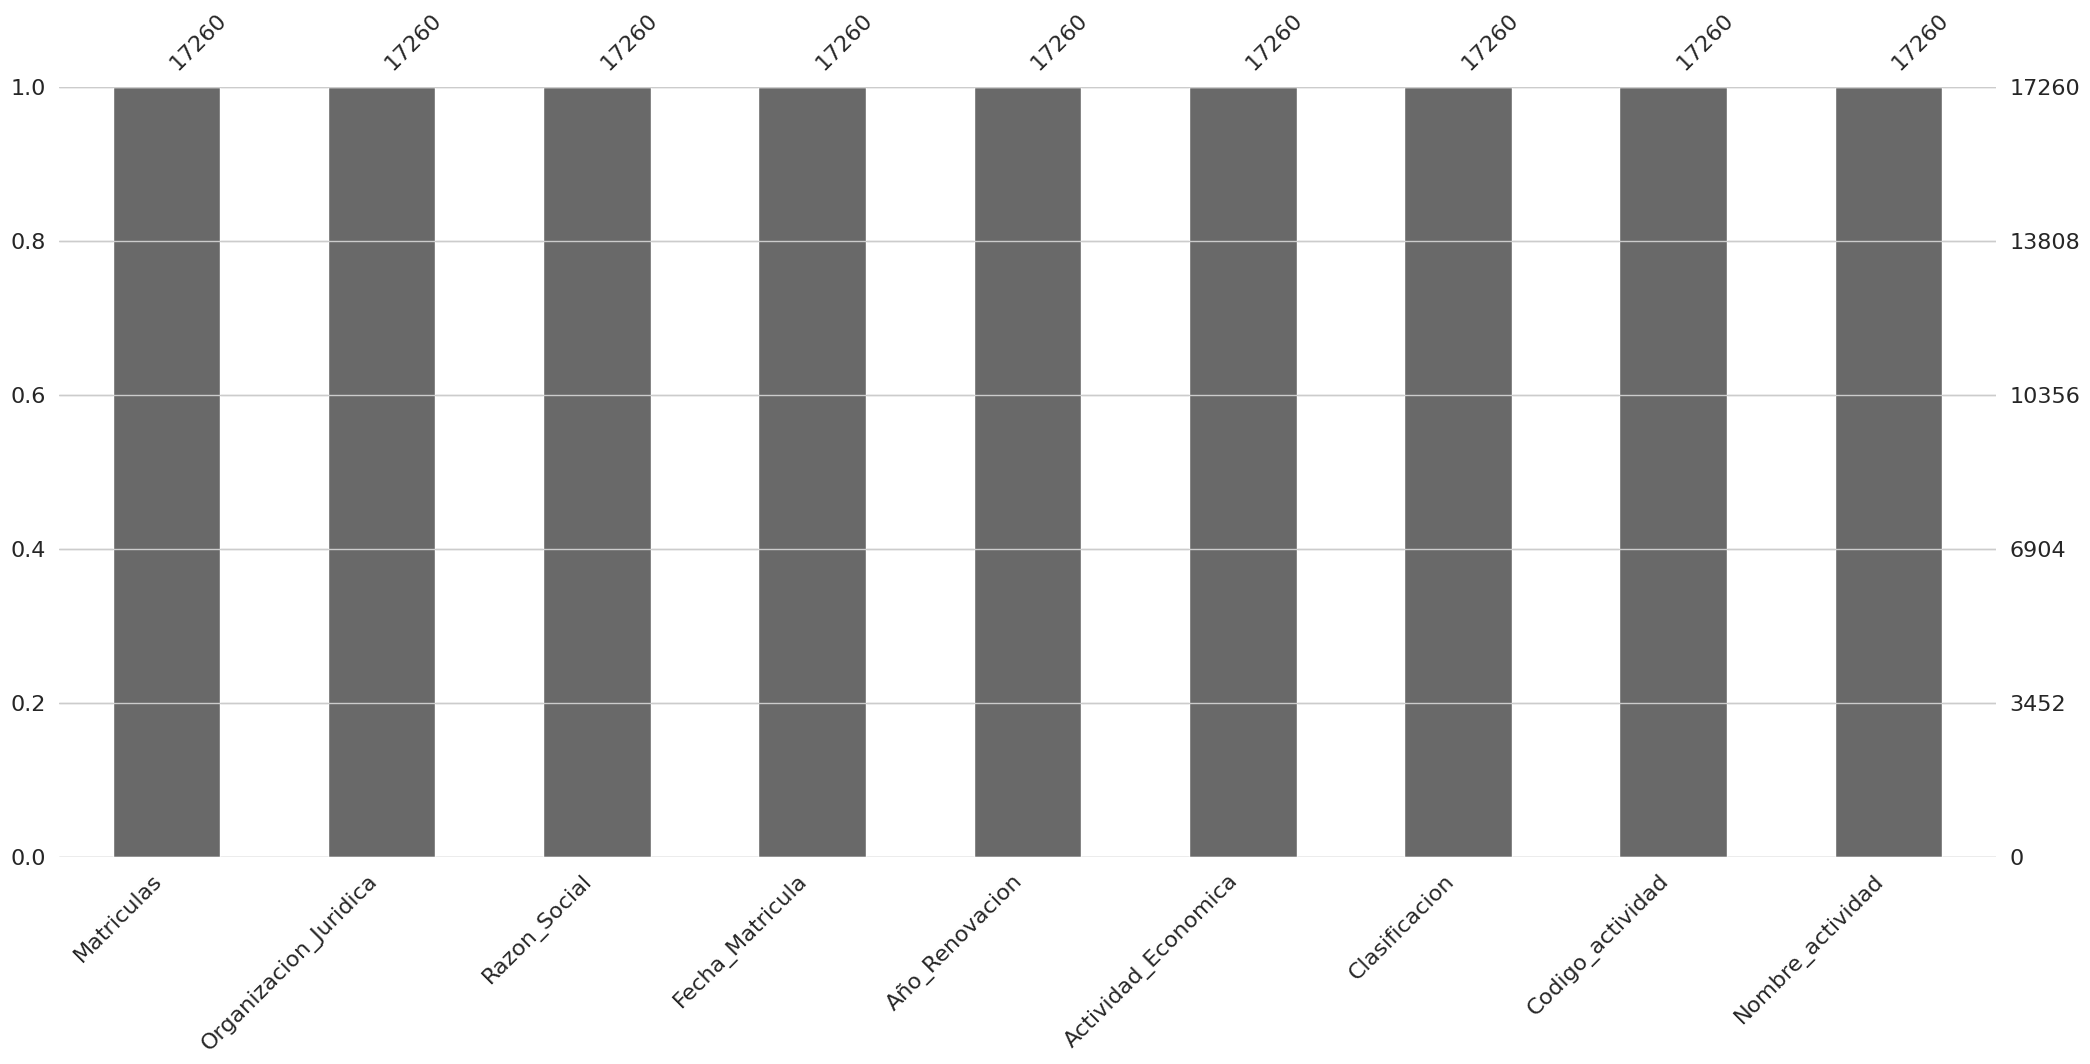

In [ ]:
plt.figure(figsize=(1, 1))
missingno.bar(df=matriculas)
plt.show()

In [ ]:
matriculas['Año_Matricula'] = matriculas['Fecha_Matricula'].dt.to_period('Y')


**Se utilizaron 4 formas de reflejar y averiguar cuantos valores nulo habia tanto en valores totales, asi como tambien el porcentaje de valores valores nulos dentro de cada variable**





#Analizar

Objetivo: Explorar los datos para encontrar patrones, tendencias o relaciones.



In [ ]:
matriculas['Clasificacion'].unique()

array(['MICROEMPRESA', 'PEQUEÑA', 'MEDIANA', 'GRANDE'], dtype=object)

In [ ]:
matriculas = matriculas.assign(Clasifica_numerica= lambda df: df.Clasificacion.replace(['MICROEMPRESA', 'PEQUEÑA', 'MEDIANA', 'GRANDE'], [1,2,3,4]) )

/tmp/ipython-input-22-637767636.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  matriculas = matriculas.assign(Clasifica_numerica= lambda df: df.Clasificacion.replace(['MICROEMPRESA', 'PEQUEÑA', 'MEDIANA', 'GRANDE'], [1,2,3,4]) )


In [ ]:
matriculas.columns

Index(['Matriculas', 'Organizacion_Juridica', 'Razon_Social',
       'Fecha_Matricula', 'Año_Renovacion', 'Actividad_Economica',
       'Clasificacion', 'Codigo_actividad', 'Nombre_actividad',
       'Año_Matricula', 'Clasifica_numerica'],
      dtype='object')

**¿Cuáles fueron los años con mayor número de matrículas para las empresas clasificadas como microempresas (Clasifica_numerica = 1) durante los últimos cinco años?**

In [ ]:
dd = matriculas.value_counts(['Año_Matricula', 'Clasifica_numerica']) \
               .reset_index(name='count') \
               .sort_values('count', ascending=False)
dd.head()

,Año_Matricula,Clasifica_numerica,count
0,2020,1,3060
1,2019,1,2576
2,2021,1,2062
3,2018,1,1579
4,2017,1,1356


El análisis del top 5 por año muestra que, entre 2017 y 2021, las microempresas (clasificación numérica 1) fueron las que más se registraron cada año.
El año 2020 registró el mayor número de matrículas con 3.060 microempresas, seguido por 2019 con 2.576 y 2021 con 2.062, evidenciando una clara tendencia de predominio de las microempresas en el registro empresarial reciente.

**¿Cuántas empresas se registraron por clasificación en los ultimos 3 años?**

In [ ]:
agrupacion_matriculas_año = matriculas.groupby(['Año_Matricula', 'Clasificacion'])['Clasifica_numerica'].size().sort_index(ascending=False)
agrupacion_matriculas_año.head(8)

Año_Matricula  Clasificacion
2021           PEQUEÑA             3
               MICROEMPRESA     2062
2020           PEQUEÑA             7
               MICROEMPRESA     3060
               GRANDE              1
2019           PEQUEÑA            14
               MICROEMPRESA     2576
               MEDIANA             2
Name: Clasifica_numerica, dtype: int64

Aqui se puede observar cuantos registros hubieron en los ultimos 3 años por cada clasificacion

**¿Cuáles son las actividades económicas más representativos en Valledupar?**

/tmp/ipython-input-26-3786332620.py:6: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


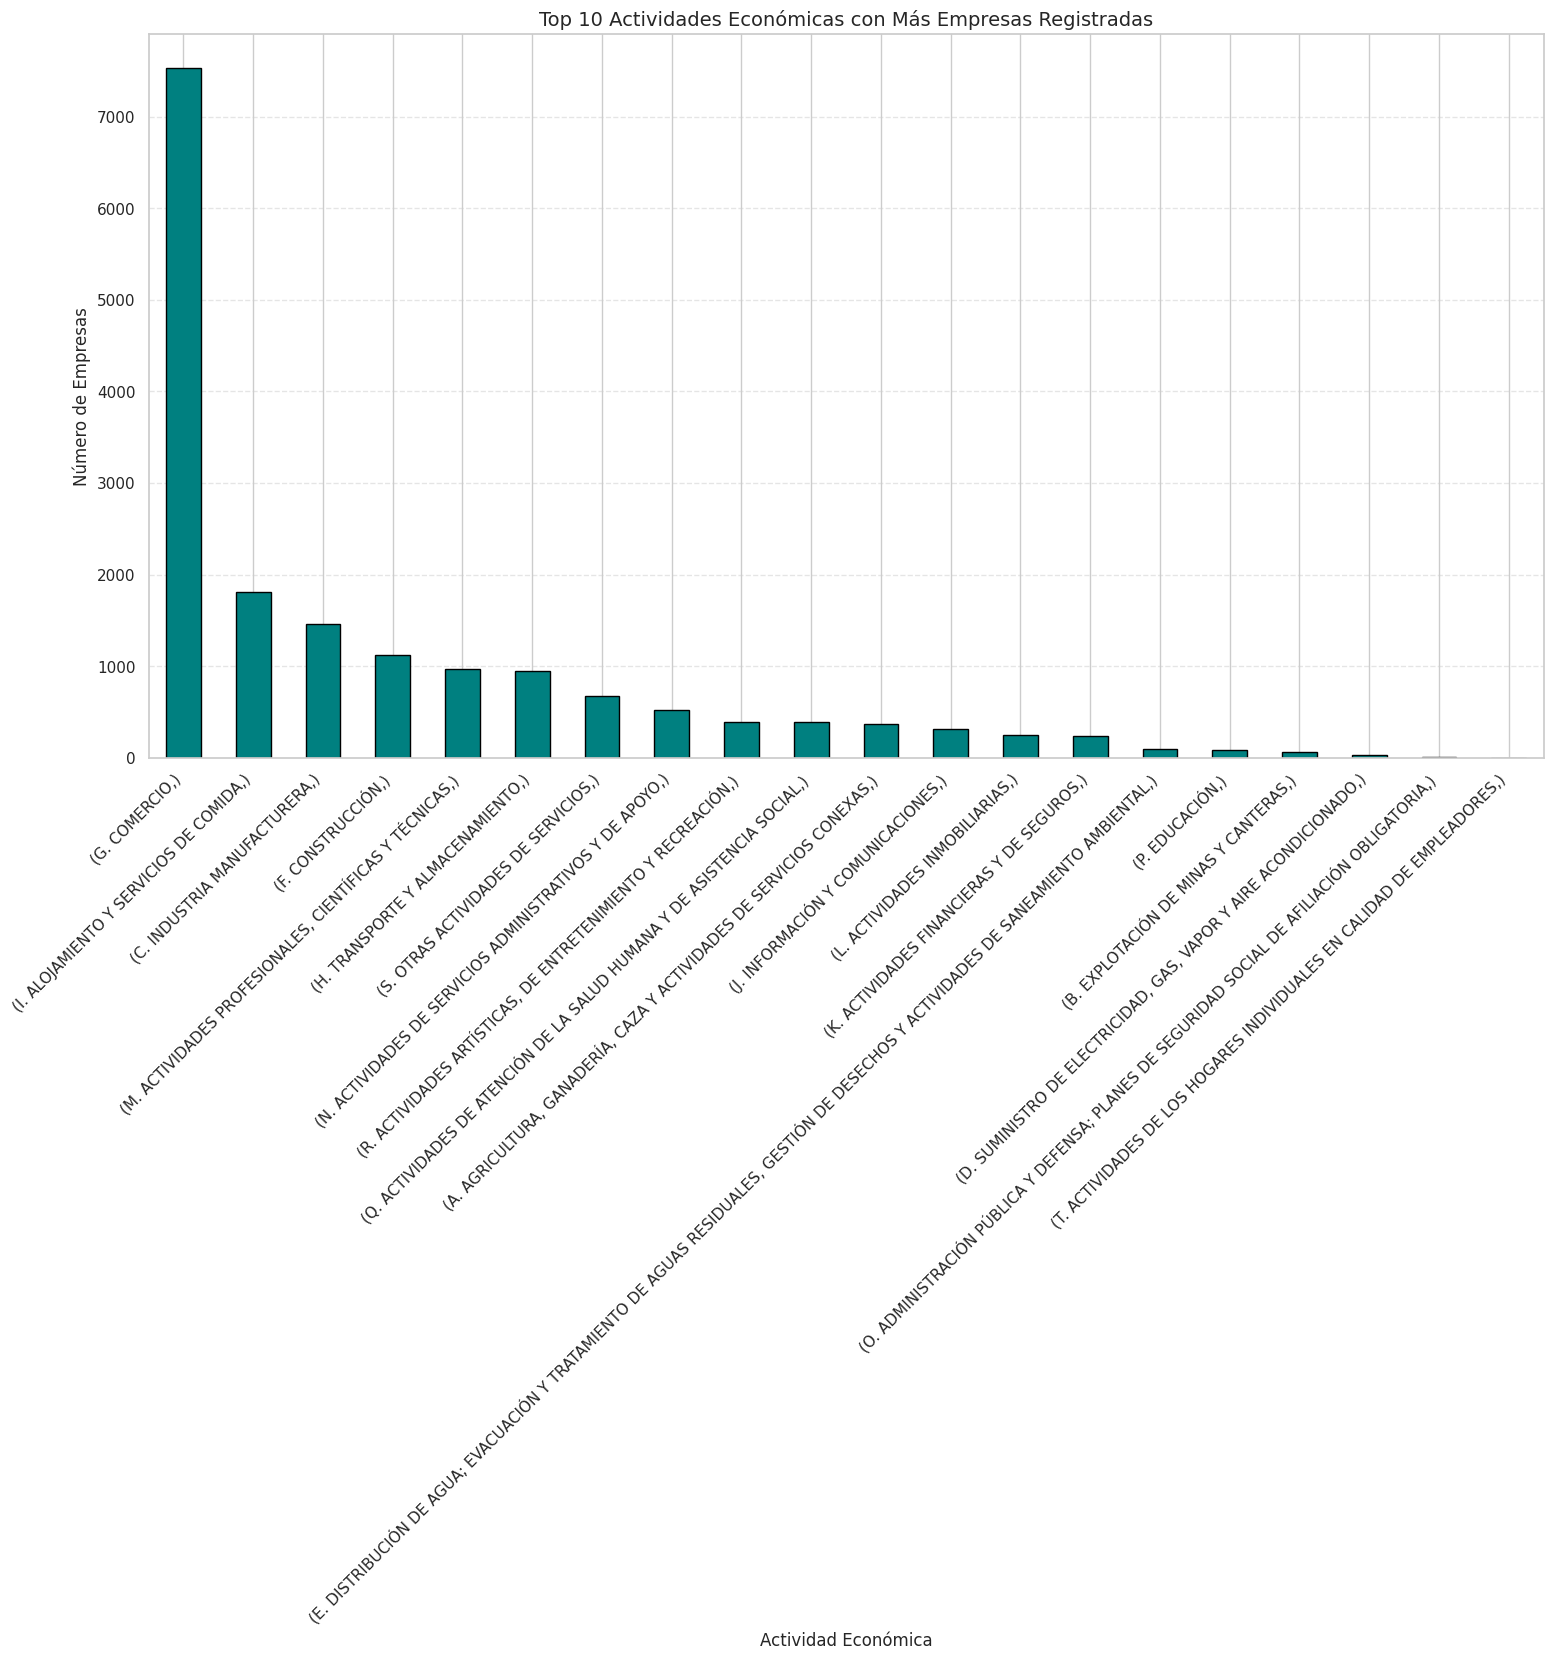

In [ ]:
matriculas.value_counts(['Actividad_Economica']).plot(kind='bar', color='teal', edgecolor='black')
plt.title('Top 10 Actividades Económicas con Más Empresas Registradas', fontsize=14)
plt.xlabel('Actividad Económica')
plt.ylabel('Número de Empresas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

G.Comercio Esta relacionada con el codigo G4729 Esta división comprende la reventa (venta sin transformación) al público en general, realizada en almacenes por departamentos, tiendas, supermercados, comisariatos, o cooperativas de consumidores, vendedores ambulantes, sistemas de ventas por teléfono o correo, entre otros, de productos nuevos y usados, para su consumo y uso personal o doméstico

In [ ]:
matriculas.query('(Codigo_actividad == "G4729")')

,Matriculas,Organizacion_Juridica,Razon_Social,Fecha_Matricula,Año_Renovacion,Actividad_Economica,Clasificacion,Codigo_actividad,Nombre_actividad,Año_Matricula,Clasifica_numerica
30,69890,PERSONA NATURAL,URIBE JAIME,2004-04-13,2021,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2004,1
197,71476,PERSONA NATURAL,VARGAS CARO KELIS,2004-09-22,2021,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2004,1
228,71831,PERSONA NATURAL,URQUIJO CANIZARES MARY LUZ,2004-11-12,2021,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2004,1
338,72303,PERSONA NATURAL,TERAN ARROYO LUIS RICARDO,2005-02-01,2020,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2005,1
413,69217,PERSONA NATURAL,TARAZONA JAIME CARLOS EDUARDO,2004-02-16,2021,G. COMERCIO,PEQUEÑA,G4729,Comercio al por menor de otros productos alime...,2004,2
...,...,...,...,...,...,...,...,...,...,...,...
16343,179173,PERSONA NATURAL,DE ARMAS DIAZ LUZ ZINDA,2021-03-09,2021,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2021,1
16599,178865,PERSONA NATURAL,MONTERROZA VILLALBA REBECA ISABEL,2021-03-02,2021,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2021,1
16646,178830,PERSONA NATURAL,ROBLES PEDRAZA BENJAMIN,2021-03-01,2021,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2021,1
17016,178412,PERSONA NATURAL,VELEZ CORRAL GERMAN,2021-02-17,2021,G. COMERCIO,MICROEMPRESA,G4729,Comercio al por menor de otros productos alime...,2021,1


**¿Qué tipo de persona (natural o jurídica) predomina?**

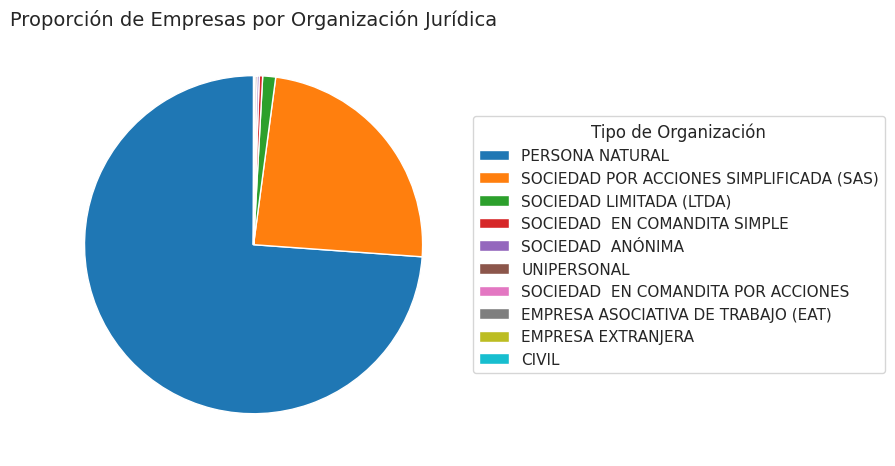

In [ ]:
proporciones = matriculas['Organizacion_Juridica'].value_counts(normalize=True)

labels = proporciones.index

plt.figure(figsize=(8, 6))
wedges, texts = plt.pie(
    proporciones,
    startangle=90,
    colors=plt.cm.tab10.colors
)
plt.title('Proporción de Empresas por Organización Jurídica', fontsize=14)
plt.ylabel('')

plt.legend(wedges, labels, title='Tipo de Organización', loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()

¿Existe alguna relacion entre la Organizacion juridica y Clasificacion?

In [ ]:
#Creamos un diccionario y una nueva columna
organizacion_codigos = {
    'SOCIEDAD POR ACCIONES SIMPLIFICADA (SAS)': 1,
    'PERSONA NATURAL': 2,
    'SOCIEDAD LIMITADA (LTDA)': 3,
    'SOCIEDAD  ANÓNIMA': 4,
    'SOCIEDAD  EN COMANDITA SIMPLE': 5,
    'UNIPERSONAL': 6,
    'EMPRESA ASOCIATIVA DE TRABAJO (EAT)': 7,
    'CIVIL': 8,
    'EMPRESA EXTRANJERA': 9,
    'SOCIEDAD  EN COMANDITA POR ACCIONES': 10
}
matriculas = matriculas.assign(
    Organiza_numerica=lambda df: df['Organizacion_Juridica'].replace(organizacion_codigos)
)


/tmp/ipython-input-29-3831148188.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Organiza_numerica=lambda df: df['Organizacion_Juridica'].replace(organizacion_codigos)


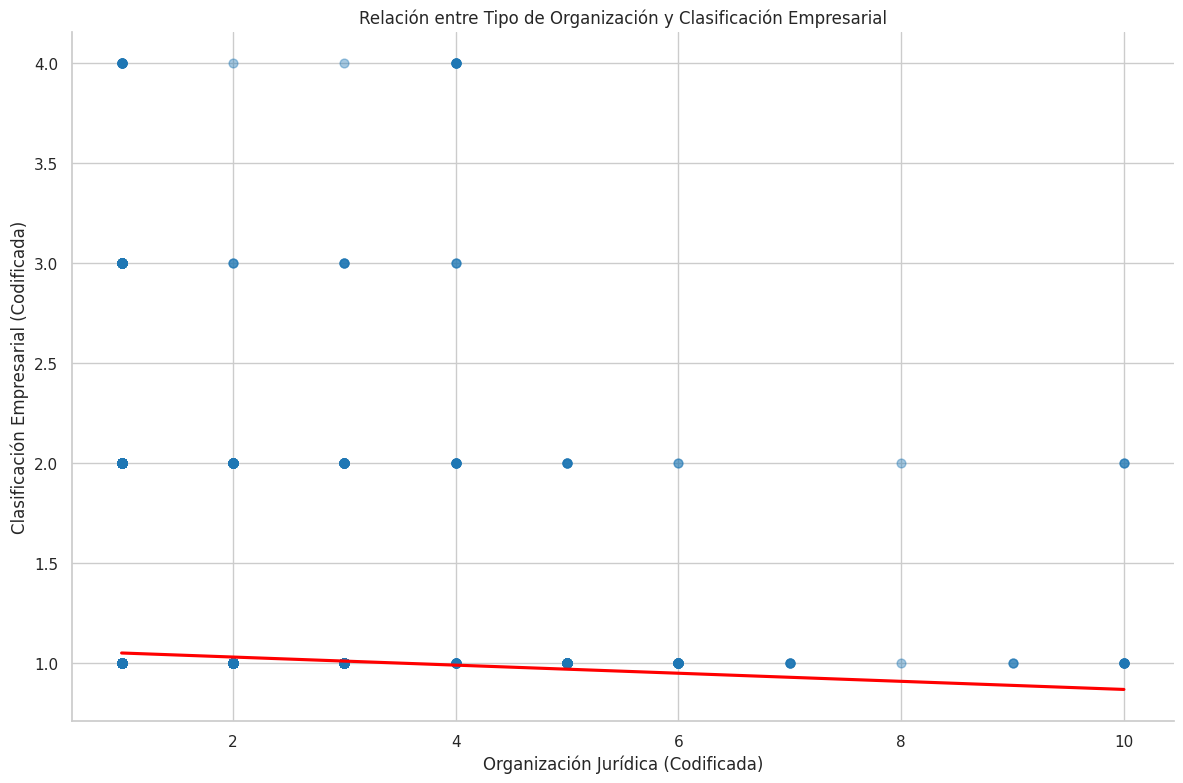

In [ ]:
sns.lmplot(
    data=matriculas,
    x='Organiza_numerica',
    y='Clasifica_numerica',
    height=8,
    aspect=1.5,
    scatter_kws={'alpha': 0.4, 's': 40},
    line_kws={'color': 'red'},
    ci=None
)

plt.title('Relación entre Tipo de Organización y Clasificación Empresarial')
plt.xlabel('Organización Jurídica (Codificada)')
plt.ylabel('Clasificación Empresarial (Codificada)')
plt.tight_layout()
plt.show()

Aunque hay una línea de regresión, las variables no tienen una relación lineal fuerte.



In [ ]:
tabla = pd.crosstab(matriculas['Organiza_numerica'], matriculas['Clasifica_numerica'])
# Prueba de chi-cuadrado
chi2, p, dof, expected = chi2_contingency(tabla)
print(f'Estadístico chi-cuadrado: {chi2:.2f}')
print(f'Valor p: {p:.4f}')

if p < 0.05:
    print("✅ Hay una relación estadísticamente significativa entre las variables.")
else:
    print("❌ No hay una relación estadísticamente significativa entre las variables.")

Estadístico chi-cuadrado: 2790.35
Valor p: 0.0000
✅ Hay una relación estadísticamente significativa entre las variables.


Existe una relación clara y estadísticamente sólida entre el tipo de organización jurídica de las empresas y su clasificación empresarial. Este vínculo no es casual y debe ser tenido en cuenta en análisis económicos, diseño de políticas públicas y segmentación empresarial.



In [ ]:
matriculas[['Clasifica_numerica', 'Organiza_numerica']].corr()

,Clasifica_numerica,Organiza_numerica
Clasifica_numerica,1.000000,-0.054361
Organiza_numerica,-0.054361,1.000000


Aunque la correlación lineal entre el tipo de organización jurídica (Organiza_numerica) y la clasificación empresarial (Clasifica_numerica) es muy débil (-0.054), la prueba de chi-cuadrado muestra un estadístico alto (2790.35) con un valor p prácticamente cero (0.0000), lo que indica una relación estadísticamente significativa entre ambas variables.

Esto significa que, aunque no existe una relación lineal directa, sí hay una asociación estructural o categórica importante: el tipo de organización jurídica influye significativamente en el tamaño o clasificación de la empresa. Las decisiones sobre la forma jurídica están relacionadas con el tipo de empresa que se constituye, pero esta relación no es proporcional ni lineal, sino de naturaleza discreta y categórica.

**¿Cómo varía la formalización empresarial por sector o año de matrícula?**

/tmp/ipython-input-33-778708010.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


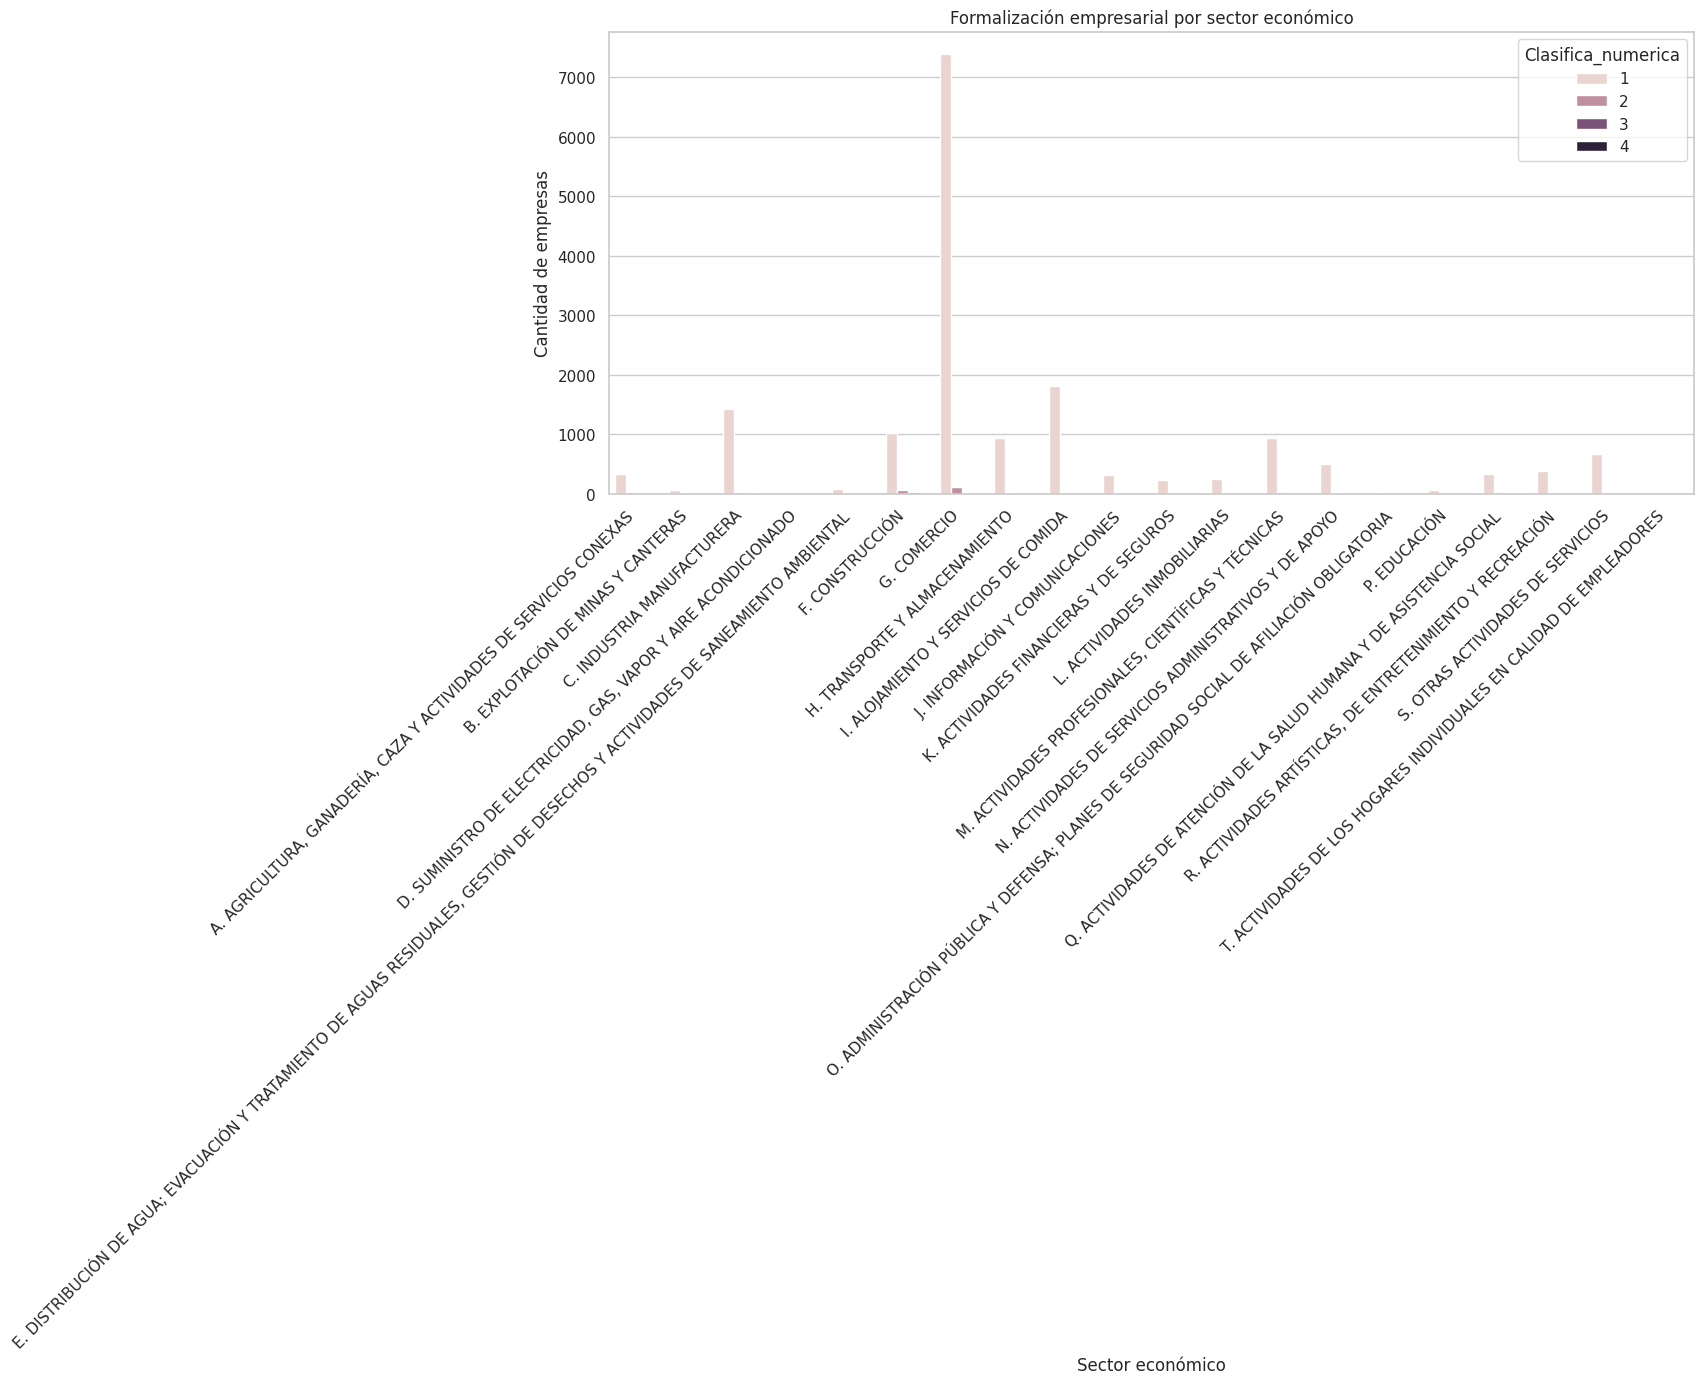

In [ ]:
# Agrupar por sector y clasificación
formalizacion_sector = matriculas.groupby(['Actividad_Economica', 'Clasifica_numerica']).size().reset_index(name='count')

plt.figure(figsize=(14, 6))
sns.barplot(
    data=formalizacion_sector,
    x='Actividad_Economica',
    y='count',
    hue='Clasifica_numerica'
)
plt.title('Formalización empresarial por sector económico')
plt.xlabel('Sector económico')
plt.ylabel('Cantidad de empresas')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

La formalización empresarial varía significativamente por sector económico y año de matrícula. Los sectores de servicios y comercio concentran la mayoría de las microempresas, lo que indica una tendencia de informalidad controlada o emprendimiento individual. A lo largo del tiempo, se puede observar un crecimiento sostenido en la creación de microempresas, especialmente en años recientes, reflejando una dinámica empresarial activa, pero aún con predominancia de estructuras jurídicas simples y escalas pequeñas.